## Here I will demonstrated how to implement HITL in a simple chatbot



![Tool node execution workflow](../images/hitl.png)




- I will be simple chatbot. But with an unnecessary complexity, i.e. at the chatnode, I will add simple approval that will take an approval from the user by asking whether user really wants to ask the question to the LLM. If yes, the quesry will be fed to the LLM, else exit. 

In [1]:
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from dotenv import load_dotenv
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START,END
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage, AIMessage
from langgraph.prebuilt import ToolNode, tools_condition

c:\Users\BSG\anaconda3\envs\llm\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\BSG\anaconda3\envs\llm\Lib\site-packages\langgraph\checkpoint\base\__init__.py:18: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [2]:
load_dotenv()

True

In [3]:
llm = ChatOpenAI(model = "gpt-4o-mini")

In [4]:
class chat_state(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [5]:
def chat_node(state:chat_state):
    decision= interrupt({
        'type': 'approval',
        'reason': "model is about to answer a user question.",
        'question': state["messages"][-1].content,
        "instruction": "Approve this question? Yes/No"
    })

    if decision["approved"] == 'no':
        return {"messages": [AIMessage(content="Not approved.")]}
    else:
        messages = state['messages']
        response = llm.invoke(messages)
        return {'messages':[response]}

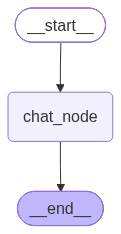

In [6]:
graph = StateGraph(chat_state)
graph.add_node("chat_node",chat_node)

graph.add_edge(START,"chat_node")
graph.add_edge('chat_node',END)

checkpointer = MemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

workflow

In [7]:
#create a new thread id for this conversation
config = {"configurable":{"thread_id":"1234"}}

# step:1  user askes a question====
initial_message = {
    "messages":[
         ("user", "explain gradient descent in very simple terms")
    ]
}

# invoke the graph for the first tiem 
result = workflow.invoke(initial_message, config=config)

In [8]:
result

{'messages': [HumanMessage(content='explain gradient descent in very simple terms', additional_kwargs={}, response_metadata={}, id='d09b8ec2-5482-430d-8452-186007eda05a')],
 '__interrupt__': [Interrupt(value={'type': 'approval', 'reason': 'model is about to answer a user question.', 'question': 'explain gradient descent in very simple terms', 'instruction': 'Approve this question? Yes/No'}, id='33dd70314e7c0d0ffd7cb1c62923e48f')]}

In [9]:
message = result['__interrupt__'][0].value
message

{'type': 'approval',
 'reason': 'model is about to answer a user question.',
 'question': 'explain gradient descent in very simple terms',
 'instruction': 'Approve this question? Yes/No'}

In [10]:
user_input = input(f" \nBackend message - {message} \n Approve this question? (y/n)")

In [11]:
final_resutl  = workflow.invoke(
    Command(resume={'approved': user_input}),
    config=config
)

In [12]:
print(final_resutl)

{'messages': [HumanMessage(content='explain gradient descent in very simple terms', additional_kwargs={}, response_metadata={}, id='d09b8ec2-5482-430d-8452-186007eda05a'), AIMessage(content='Sure! Imagine you\'re at the top of a hill and you want to find the lowest point in the valley. Instead of looking around to find the best way down, you take small steps in the direction that\'s steepest downhill. \n\nGradient descent is a bit like that! \n\n1. **Starting Point:** You start at a random point (like the top of the hill) with your guesses about solving a problem.\n2. **Looking Around:** You look to see which way goes down the most steeply (that’s the "gradient"), telling you how to improve your guess.\n3. **Taking a Step:** You take a step in that direction but not too big, so you don’t overshoot.\n4. **Repeat:** You keep repeating this process: checking the slope and taking small steps down until you reach the bottom, or the best solution.\n\nIn short, gradient descent is a method us

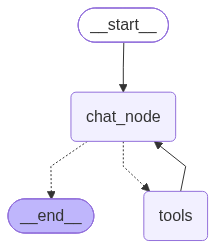

In [28]:
result = workflow.invoke({
    "messages": [HumanMessage(
        content=("Using the pdf I uploaded, explain how to spit a node in decision tree?")
    )]
})



In [29]:
print(result['messages'][-1].content)

To split a node in a decision tree, the algorithm follows these steps:

1. **Search for Tests**: The algorithm searches over all possible tests (conditions) that can be applied to the data. Each possible test evaluates whether a feature satisfies a particular condition. 

2. **Select the Most Informative Test**: The goal is to find the test that provides the most information about the target variable. This means selecting a test that best separates the classes present in the dataset.

3. **Perform the Split**: Once the best test is identified, the dataset is divided based on the result of this test. For example, if the test evaluates whether a feature value is less than or equal to a certain threshold, the dataset is split into two groups: one that meets the test condition (e.g., values less than or equal to the threshold) and another that does not.

4. **Building Nodes**: After splitting the dataset, each new subset of data forms a new node in the tree. The left node will contain data